# 05 — Modelagem, validação e overfitting

Vamos comparar **duas famílias de algoritmos**, com **quatro configurações de complexidade por família**, e investigar a diferença de desempenho entre ajuste e dados não usados no ajuste.

**Ordem:** definir protocolo → comparar por validação cruzada no treino → congelar um finalista por família → apresentar a comparação de treino e teste exigida no roteiro. As métricas de teste não serão usadas para escolher ou refazer os hiperparâmetros.

**Entradas:** conjuntos gerados no notebook 02. O pré-processamento de `src/` é ajustado novamente dentro de cada partição. Ainda não escolhemos o modelo de produção nem o ponto de corte financeiro.


## 1. Carregar o treino e as funções reutilizáveis

O alvo continua separado dos atributos. A base de teste será carregada somente depois de registrar os finalistas definidos pela validação.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

relativo = Path("data/processed/treino.csv")
raiz = None
for pasta in (Path.cwd(), *Path.cwd().parents):
    if (pasta / relativo).is_file():
        raiz = pasta
        break
if raiz is None:
    raise FileNotFoundError("Execute o notebook 02 para gerar os conjuntos.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.modeling import (
    configuracoes_modelos, comparar_validacao,
    selecionar_finalistas, avaliar_treino_teste,
)

metadados = json.loads((raiz / "data/processed/separacao.json").read_text())
caminho_treino = raiz / relativo
assert hashlib.sha256(caminho_treino.read_bytes()).hexdigest() == metadados["sha256_treino"]
treino = pd.read_csv(caminho_treino)
X_train = treino.drop(columns="loan_status")
y_train = treino["loan_status"]
pasta_resultados = raiz / "docs/resultados"
pasta_resultados.mkdir(parents=True, exist_ok=True)
pasta_figuras = raiz / "docs/figuras"
pasta_figuras.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print(f"Treino: {len(treino):,} registros. O teste ainda não foi carregado.")


Treino: 25,932 registros. O teste ainda não foi carregado.


## 2. Protocolo e configurações definidas antes da avaliação

| Família | Controle de complexidade | Valores | Pré-processamento |
| --- | --- | --- | --- |
| Regressão Logística | `C`, inverso da força de regularização | 0,01; 0,1; 1; 10 | Imputação, variável calculada, codificação e padronização |
| Random Forest | `max_depth` | 3; 6; 10; sem limite | Mesmas regras, imputação, variável e codificação, sem padronizar |

Na Regressão Logística, aumentar `C` reduz a regularização, mas mantém uma fronteira linear no espaço dos atributos. Na Random Forest, aumentar a profundidade permite relações mais detalhadas e maior risco de memorizar o ajuste. Fixamos 100 árvores; os outros hiperparâmetros não participam desta busca.

**Validação:** `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`, com as mesmas partições para as oito configurações. São 24 ajustes na busca. Cada ajuste inclui as regras, imputação, cálculo da variável, encoding, escala quando aplicável e o classificador.

**Desbalanceamento:** ambos os estimadores usam `class_weight="balanced"`, calculado a partir do alvo da respectiva partição de ajuste. Não há reamostragem nem modificação da distribuição de validação ou teste.

**Critério de escolha:** maior ROC-AUC média de validação dentro de cada família; desempate por F1 médio e, depois, menor complexidade na ordem predefinida. ROC-AUC avalia a ordenação dos scores em diferentes limiares. Recall e F1 ajudam a interpretar a classe inadimplente. O ponto de corte inicial é 0,5 (classe 1 quando o score é maior ou igual ao corte); a decisão financeira virá na próxima etapa. Os scores não são considerados probabilidades calibradas apenas por usar `predict_proba`.


In [2]:
configuracoes = configuracoes_modelos()
display(pd.DataFrame(configuracoes))
assert len(configuracoes) == 8
assert pd.DataFrame(configuracoes).groupby("familia").size().eq(4).all()


,id,familia,parametro,valor,rotulo
0,rl_C_0.01,regressao_logistica,C,0.01,C=0.01
1,rl_C_0.1,regressao_logistica,C,0.10,C=0.1
2,rl_C_1,regressao_logistica,C,1.00,C=1
3,rl_C_10,regressao_logistica,C,10.00,C=10
4,rf_depth_3,random_forest,max_depth,3.00,profundidade=3
5,rf_depth_6,random_forest,max_depth,6.00,profundidade=6
6,rf_depth_10,random_forest,max_depth,10.00,profundidade=10
7,rf_depth_None,random_forest,max_depth,NaN,profundidade=sem limite


## 3. Executar a validação cruzada no treino

As colunas `*_treino_cv` são médias no ajuste de cada fold; `*_validacao_cv` são médias nos registros excluídos daquele ajuste. `*_desvio_cv` é o desvio padrão entre os três folds, não um intervalo de confiança. Uma diferença positiva grande entre ajuste e validação sugere risco de overfitting.

Os resultados completos ficam em `docs/resultados/comparacao_validacao.csv`. Nenhuma tabela globalmente imputada é passada à validação cruzada.


In [3]:
resultados_cv = comparar_validacao(X_train, y_train, n_splits=3)
resultados_cv.to_csv(pasta_resultados / "comparacao_validacao.csv", index=False)
colunas_cv = ["configuracao", "roc_auc_treino_cv", "roc_auc_validacao_cv", "roc_auc_desvio_cv",
              "f1_treino_cv", "f1_validacao_cv", "recall_validacao_cv", "gap_roc_auc_cv"]
display(resultados_cv[colunas_cv].round(4))


,configuracao,roc_auc_treino_cv,roc_auc_validacao_cv,roc_auc_desvio_cv,f1_treino_cv,f1_validacao_cv,recall_validacao_cv,gap_roc_auc_cv
0,rl_C_0.01,0.8703,0.8694,0.0064,0.6370,0.6374,0.7796,0.0009
1,rl_C_0.1,0.8737,0.8725,0.0058,0.6441,0.6438,0.7798,0.0012
2,rl_C_1,0.8742,0.8729,0.0054,0.6460,0.6452,0.7789,0.0013
3,rl_C_10,0.8742,0.8729,0.0053,0.6460,0.6447,0.7778,0.0013
4,rf_depth_3,0.8858,0.8846,0.0027,0.6781,0.6761,0.7524,0.0012
5,rf_depth_6,0.9152,0.9087,0.0020,0.7487,0.7393,0.7699,0.0065
6,rf_depth_10,0.9564,0.9269,0.0019,0.8333,0.7767,0.7560,0.0295
7,rf_depth_None,1.0000,0.9284,0.0008,0.9989,0.8068,0.7450,0.0716


Validação: rl_C_0.01
Validação: rl_C_0.1
Validação: rl_C_1
Validação: rl_C_10
Validação: rf_depth_3
Validação: rf_depth_6
Validação: rf_depth_10
Validação: rf_depth_None


## 4. Congelar um finalista por família antes de consultar o teste

O arquivo `selecao_modelos.json` registra as configurações escolhidas e o protocolo. A próxima etapa usará esses candidatos para analisar custos dos erros e definir o ponto de corte com validação interna ao treino. Não escolhemos um vencedor de produção com a métrica do teste.


In [4]:
finalistas = selecionar_finalistas(resultados_cv)
ids_finalistas = finalistas["configuracao"].tolist()
selecao = {
    "criterio": "Maior ROC-AUC media de validacao; desempate por F1 medio e menor complexidade.",
    "n_splits": 3, "random_state": 42, "class_weight": "balanced",
    "threshold_comparacao": 0.5,
    "sha256_treino": metadados["sha256_treino"],
    "sha256_teste": metadados["sha256_teste"],
    "versao_sklearn": sklearn.__version__,
    "configuracoes_avaliadas": configuracoes,
    "finalistas": finalistas.to_dict(orient="records"),
    "proxima_etapa": "Escolha financeira e threshold por validacao no treino; sem nova busca orientada pelo teste.",
}
caminho_selecao = pasta_resultados / "selecao_modelos.json"
caminho_selecao.write_text(json.dumps(selecao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
hash_selecao = hashlib.sha256(caminho_selecao.read_bytes()).hexdigest()
display(finalistas[colunas_cv].round(4))
print("Finalistas registrados antes da leitura do teste:", ids_finalistas)


,configuracao,roc_auc_treino_cv,roc_auc_validacao_cv,roc_auc_desvio_cv,f1_treino_cv,f1_validacao_cv,recall_validacao_cv,gap_roc_auc_cv
0,rf_depth_None,1.0000,0.9284,0.0008,0.9989,0.8068,0.7450,0.0716
1,rl_C_10,0.8742,0.8729,0.0053,0.6460,0.6447,0.7778,0.0013


Finalistas registrados antes da leitura do teste: ['rf_depth_None', 'rl_C_10']


## 5. Gráfico de ajuste versus validação

As barras de erro mostram o desvio padrão entre folds. Pequenas diferenças entre médias, quando próximas da variação entre folds, não demonstram uma superioridade estatística definitiva. O protocolo usa a maior média para obter uma escolha reproduzível.


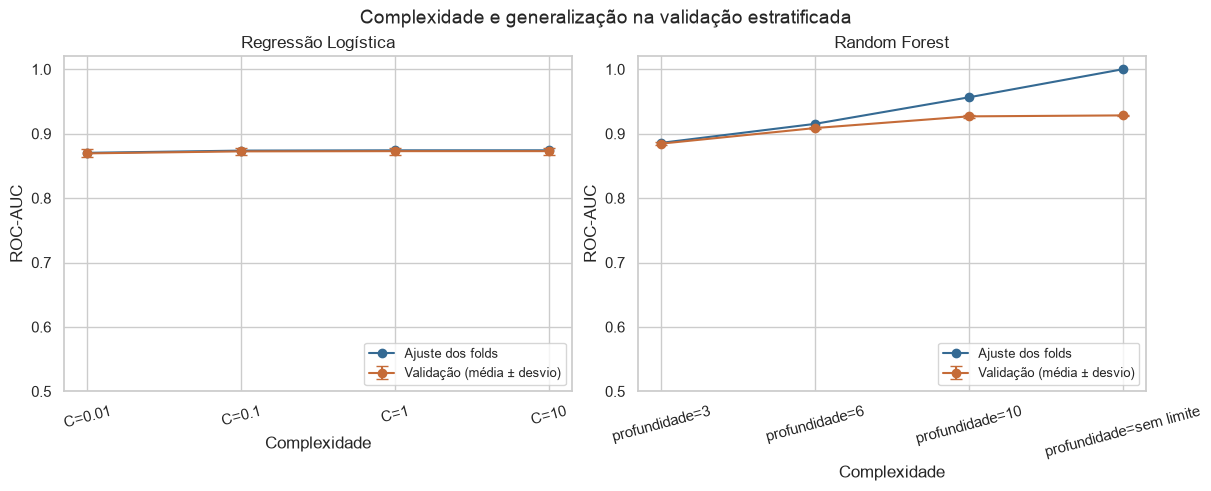

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, familia, titulo in zip(axes, ["regressao_logistica", "random_forest"],
                              ["Regressão Logística", "Random Forest"]):
    parte = resultados_cv[resultados_cv["familia"] == familia]
    posicoes = np.arange(len(parte))
    ax.plot(posicoes, parte["roc_auc_treino_cv"], marker="o", label="Ajuste dos folds", color="#356A93")
    ax.errorbar(posicoes, parte["roc_auc_validacao_cv"], yerr=parte["roc_auc_desvio_cv"],
                marker="o", capsize=4, label="Validação (média ± desvio)", color="#C56B38")
    ax.set_xticks(posicoes, parte["complexidade"], rotation=15)
    ax.set(title=titulo, ylabel="ROC-AUC", xlabel="Complexidade", ylim=(0.5, 1.02))
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle("Complexidade e generalização na validação estratificada", fontsize=14)
fig.savefig(pasta_figuras / "05_validacao_modelos.png", dpi=160)
display(fig)
plt.close(fig)


## 6. Comparação congelada de treino e teste exigida no roteiro

Somente agora carregamos os 6.484 registros de teste. Ajustamos cada uma das oito configurações no treino completo e calculamos ROC-AUC, F1 e recall nos dois conjuntos, com ponto de corte 0,5. Não realizamos `fit` sobre o teste. Essa tabela complementa a validação e mostra o risco de overfitting; ela não reabre a seleção de hiperparâmetros.

O roteiro pede métricas de teste para diferentes complexidades. Essa exposição reduz a independência do teste caso sejam tomadas novas decisões a partir dela. Por isso congelamos os candidatos antes da leitura e manteremos toda escolha de limiar e custo na validação do treino, sem adaptar o protocolo aos resultados de teste.


In [6]:
caminho_teste = raiz / "data/processed/teste.csv"
assert hashlib.sha256(caminho_teste.read_bytes()).hexdigest() == metadados["sha256_teste"]
teste = pd.read_csv(caminho_teste)
X_test = teste.drop(columns="loan_status")
y_test = teste["loan_status"]
assert len(teste) == metadados["registros_teste"]
assert list(X_train.columns) == list(X_test.columns)

resultados_finais = avaliar_treino_teste(X_train, y_train, X_test, y_test)
resultados_finais["finalista_por_cv"] = resultados_finais["configuracao"].isin(ids_finalistas)
resultados_finais.to_csv(pasta_resultados / "comparacao_treino_teste.csv", index=False)
assert hashlib.sha256(caminho_selecao.read_bytes()).hexdigest() == hash_selecao
display(resultados_finais.round(4))


,configuracao,familia,complexidade,threshold,roc_auc_treino,f1_treino,recall_treino,roc_auc_teste,f1_teste,recall_teste,gap_roc_auc,finalista_por_cv
0,rl_C_0.01,regressao_logistica,C=0.01,0.5,0.8712,0.6399,0.7806,0.8698,0.6428,0.7729,0.0014,False
1,rl_C_0.1,regressao_logistica,C=0.1,0.5,0.8736,0.6443,0.7812,0.8717,0.6478,0.7750,0.0019,False
2,rl_C_1,regressao_logistica,C=1,0.5,0.8739,0.6456,0.7817,0.8719,0.6480,0.7750,0.0020,False
3,rl_C_10,regressao_logistica,C=10,0.5,0.8739,0.6450,0.7806,0.8720,0.6480,0.7743,0.0020,True
4,rf_depth_3,random_forest,profundidade=3,0.5,0.8850,0.6851,0.7501,0.8815,0.6882,0.7511,0.0036,False
5,rf_depth_6,random_forest,profundidade=6,0.5,0.9141,0.7467,0.7746,0.9052,0.7487,0.7722,0.0089,False
6,rf_depth_10,random_forest,profundidade=10,0.5,0.9504,0.8217,0.7930,0.9233,0.7904,0.7630,0.0271,False
7,rf_depth_None,random_forest,profundidade=sem limite,0.5,1.0000,0.9996,1.0000,0.9299,0.8198,0.7525,0.0701,True


Avaliação congelada: rl_C_0.01
Avaliação congelada: rl_C_0.1
Avaliação congelada: rl_C_1
Avaliação congelada: rl_C_10
Avaliação congelada: rf_depth_3
Avaliação congelada: rf_depth_6
Avaliação congelada: rf_depth_10
Avaliação congelada: rf_depth_None


## 7. Gráfico de treino versus teste

O treino completo é maior que cada partição usada na validação cruzada. Por isso estas métricas de treino não são as mesmas médias de ajuste da seção 3. Um aumento no desempenho de treino sem melhora equivalente fora do ajuste evidencia o efeito do aumento da complexidade.


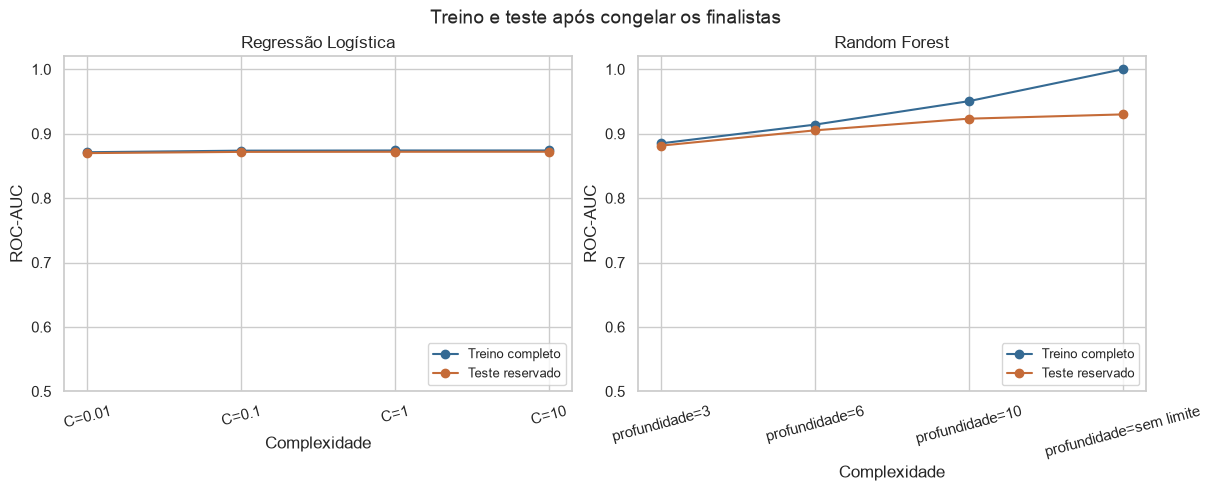

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, familia, titulo in zip(axes, ["regressao_logistica", "random_forest"],
                              ["Regressão Logística", "Random Forest"]):
    parte = resultados_finais[resultados_finais["familia"] == familia]
    posicoes = np.arange(len(parte))
    ax.plot(posicoes, parte["roc_auc_treino"], marker="o", label="Treino completo", color="#356A93")
    ax.plot(posicoes, parte["roc_auc_teste"], marker="o", label="Teste reservado", color="#C56B38")
    ax.set_xticks(posicoes, parte["complexidade"], rotation=15)
    ax.set(title=titulo, ylabel="ROC-AUC", xlabel="Complexidade", ylim=(0.5, 1.02))
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle("Treino e teste após congelar os finalistas", fontsize=14)
fig.savefig(pasta_figuras / "06_overfitting_modelos.png", dpi=160)
display(fig)
plt.close(fig)


## 8. Diagnóstico de overfitting e configurações finalistas

**Regressão Logística:** a ROC-AUC de validação cresce de 0,8694 (`C=0,01`) para 0,8729 (`C=10`), com diferenças de ajuste e validação próximas de 0,0013 ou menos. Não há evidência de overfitting acentuado nesse intervalo. `C=10` vence pelo critério predefinido, mas sua vantagem sobre `C=1` é de aproximadamente 0,00003, muito menor que a variação entre folds; não representa superioridade estatística demonstrada.

**Random Forest:** a diferença de ROC-AUC entre ajuste e validação cresce de 0,0012 na profundidade 3 para 0,0065 na 6, 0,0295 na 10 e 0,0716 sem limite. O aumento fica mais evidente na profundidade 10; sem limite, a ROC-AUC de ajuste chega a 1,0000, enquanto a validação fica em 0,9284. Isso evidencia memorização do ajuste. O ganho de validação de profundidade 10 (0,9269) para sem limite (0,9284) é pequeno frente ao aumento do gap. A profundidade 10 oferece menor sobreajuste; o protocolo fixado, porém, escolhe a maior média de validação, que neste experimento é a floresta sem limite. O controle de complexidade mostrou o custo desse ganho, sem escolher o modelo pelo desempenho de treino.

**Finalistas definidos por CV:** Regressão Logística com `C=10` e Random Forest com `max_depth=None`. A floresta tem a melhor ROC-AUC e F1 de validação, mas menor recall no corte 0,5 (0,7450 contra 0,7778 da logística). Portanto, o melhor ranking não equivale automaticamente à menor perda por inadimplência.

**Avaliação congelada no teste:** a logística apresenta ROC-AUC 0,8720, F1 0,6480 e recall 0,7743. A floresta apresenta ROC-AUC 0,9299, F1 0,8198 e recall 0,7525. O gap treino–teste é 0,0020 na logística e 0,0701 na floresta. Esses números confirmam a necessidade de distinguir ajuste e generalização; não alteram os finalistas nem justificam nova busca a partir do teste.

A escolha de produção e o threshold continuam pendentes. Os resultados são de uma base e de uma divisão específicas; não garantem comportamento igual em dados futuros.



## 9. Próxima etapa: decisão financeira e ponto de corte

O maior ROC-AUC não determina sozinho o menor prejuízo. Para os dois finalistas, vamos produzir relatórios de classificação e matrizes de confusão, explicitar hipóteses de custo para falsos positivos e falsos negativos e escolher o ponto de corte com previsões de validação no treino. O teste será usado para reportar o resultado das decisões já definidas, sem nova busca de hiperparâmetros.

O pipeline campeão e seu ponto de corte serão salvos com `joblib` após essa decisão. Nenhum candidato é declarado pronto para concessão real de crédito: as definições da base, disponibilidade temporal dos atributos e qualidade das probabilidades continuam sendo limitações do projeto educacional.


In [8]:
assert hashlib.sha256(caminho_treino.read_bytes()).hexdigest() == metadados["sha256_treino"]
assert hashlib.sha256(caminho_teste.read_bytes()).hexdigest() == metadados["sha256_teste"]
assert hashlib.sha256(caminho_selecao.read_bytes()).hexdigest() == hash_selecao
assert len(resultados_cv) == len(resultados_finais) == 8
assert resultados_finais["finalista_por_cv"].sum() == 2
print("Oito configurações comparadas; dois finalistas definidos por validação.")
print("Dados preservados e seleção sem alteração após a avaliação de teste.")


Oito configurações comparadas; dois finalistas definidos por validação.
Dados preservados e seleção sem alteração após a avaliação de teste.
